In [2]:
import sys
from pathlib import Path

# 현재 파일 기준 상위 폴더 경로를 sys.path에 추가
parent_dir = Path.cwd().parent
sys.path.append(str(parent_dir))

In [1]:
ps = {2: 1/36, 3: 2/36, 4: 3/36, 5: 4/36, 6: 5/36, 7: 6/36, 8: 5/36, 9: 4/36, 10: 3/36, 11: 2/36, 12: 1/36}


In [3]:
V = 0

for x, p in ps.items():
    V += x*p

print(V)

6.999999999999999


In [3]:
import numpy as np


def sample(dices=2):
    x = 0
    for _ in range(dices):
        x += np.random.choice([1, 2, 3, 4, 5, 6])
    return x

print(sample())
print(sample())
print(sample())

6
5
6


In [10]:
trial = 100

samples = []
for _ in range(trial):
    s = sample()
    samples.append(s)

V = sum(samples) / len(samples)
print(V)

7.03


In [13]:
trial = 100

samples = []
for _ in range(trial):
    s = sample()
    samples.append(s)
    V = sum(samples) / len(samples)
    print(V)

6.0
6.5
8.0
7.25
6.6
7.0
6.714285714285714
6.5
6.222222222222222
6.6
6.7272727272727275
6.833333333333333
6.846153846153846
6.714285714285714
6.8
6.875
7.0588235294117645
7.055555555555555
6.947368421052632
6.95
6.809523809523809
6.590909090909091
6.782608695652174
6.708333333333333
6.88
6.923076923076923
6.814814814814815
6.75
6.793103448275862
6.933333333333334
7.032258064516129
7.03125
6.96969696969697
6.911764705882353
6.828571428571428
6.833333333333333
6.8108108108108105
6.7631578947368425
6.717948717948718
6.8
6.780487804878049
6.761904761904762
6.837209302325581
6.818181818181818
6.8
6.760869565217392
6.808510638297872
6.875
6.918367346938775
6.98
7.0588235294117645
6.980769230769231
7.056603773584905
7.037037037037037
7.0
7.071428571428571
7.12280701754386
7.120689655172414
7.186440677966102
7.183333333333334
7.131147540983607
7.161290322580645
7.142857142857143
7.125
7.107692307692307
7.121212121212121
7.104477611940299
7.102941176470588
7.101449275362318
7.042857142857143
7.

In [14]:
trial = 1000
V, n = 0, 0

for _ in range(trial):
    s = sample()
    n += 1
    V += (s - V) / n
    print(V)


4.0
5.5
5.333333333333333
6.0
5.8
6.0
6.285714285714286
6.25
6.333333333333333
6.8
6.818181818181818
6.916666666666667
6.846153846153847
6.857142857142858
6.666666666666667
6.8125
6.823529411764706
6.888888888888888
6.789473684210526
6.85
6.761904761904762
6.818181818181818
6.869565217391305
6.875
6.92
6.923076923076923
7.037037037037037
7.035714285714286
7.0344827586206895
7.166666666666666
7.032258064516128
7.062499999999999
6.999999999999999
7.058823529411764
7.0857142857142845
7.083333333333332
7.027027027027026
6.973684210526315
6.999999999999999
6.8999999999999995
6.926829268292682
6.809523809523808
6.9069767441860455
7.022727272727272
7.088888888888888
7.108695652173912
7.085106382978722
6.979166666666665
6.918367346938774
6.979999999999998
7.058823529411763
7.096153846153844
7.0377358490566015
7.055555555555554
7.090909090909089
7.178571428571427
7.1578947368421035
7.189655172413792
7.1864406779661
7.133333333333332
7.114754098360654
7.11290322580645
7.079365079365078
6.9999999

In [17]:
from common.gridworld import GridWorld

env = GridWorld()
action = 0
next_state, reward, done = env.step(action)

print('next_state', next_state)
print('reward', reward)
print('done', done)

next_state (1, 0)
reward 0
done False


In [30]:
def format_data(obj):
    if isinstance(obj, (dict, defaultdict)):
        # defaultdict를 일반 dict로 변환하며 내부 키/값 포맷팅
        return {format_data(k): format_data(v) for k, v in obj.items()}
    elif isinstance(obj, tuple):
        # 튜플 내부 요소 포맷팅
        return tuple(format_data(x) for x in obj)
    elif isinstance(obj, list):
        # 리스트 내부 요소 포맷팅
        return [format_data(x) for x in obj]
    elif isinstance(obj, (np.integer, int)):
        # numpy 정수를 기본 int로 변환
        return int(obj)
    elif isinstance(obj, (np.floating, float)):
        # 실수는 소수점 이하 2자리까지만 출력
        return round(float(obj), 2)
    return obj

In [37]:
from collections import defaultdict
import numpy as np
from common.gridworld import GridWorld


class RandomAgent:
    def __init__(self):
        self.gamma = 0.9
        self.action_size = 4

        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.V = defaultdict(lambda: 0)
        self.cnts = defaultdict(lambda: 0)
        self.memory = []

    def get_action(self, state):
        action_probs = self.pi[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def add(self, state, action, reward):
        data = (state, action, reward)
        self.memory.append(data)

    def reset(self):
        self.memory.clear()

    def eval(self, DEBUG=False):
        G = 0
        if DEBUG: 
            clean_data = [(state, int(action), reward) for state, action, reward in self.memory]
            print('self.memory',clean_data)
        for data in reversed(self.memory):  # 역방향으로(reserved) 따라가기
            state, action, reward = data
            if DEBUG: print((state, int(action), reward))
            G = self.gamma * G + reward
            if DEBUG: print('G',G)
            self.cnts[state] += 1
            self.V[state] += (G - self.V[state]) / self.cnts[state]
            if DEBUG: print('V',format_data(self.V))

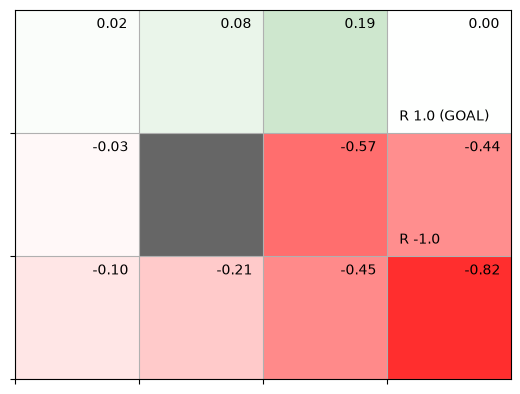

In [39]:
env = GridWorld()
agent = RandomAgent()

episodes = 1000
for episode in range(episodes):  # 에피소드 1000번 수행
    state = env.reset()
    agent.reset()
    
    while True:
        action = agent.get_action(state)             # 행동 선택
        next_state, reward, done = env.step(action)  # 행동 수행

        agent.add(state, action, reward)  # (상태, 행동, 보상) 저장
        if done:   # 목표에 도달 시
            agent.eval()  # 몬테카를로법으로 가치 함수 갱신
            break         # 다음 에피소드 시작

        state = next_state

# [그림 5-12] 몬테카를로법으로 얻은 가치 함수
env.render_v(agent.V)


In [40]:
env = GridWorld()
agent = RandomAgent()

episodes = 2
for episode in range(episodes):  # 에피소드 1000번 수행
    print('#'*10)
    print('episode',episode)
    state = env.reset()
    agent.reset()
    print('state',state)
    while True:
        action = agent.get_action(state)             # 행동 선택
        #print('action',action)
        next_state, reward, done = env.step(action)  # 행동 수행
        
        print('action',action,' -> (',next_state, reward, done,')')
        agent.add(state, action, reward)  # (상태, 행동, 보상) 저장
        if done:   # 목표에 도달 시
            agent.eval(DEBUG=True)  # 몬테카를로법으로 가치 함수 갱신
            #print(agent.V)
            break         # 다음 에피소드 시작

        state = next_state

# [그림 5-12] 몬테카를로법으로 얻은 가치 함수
#env.render_v(agent.V)


##########
episode 0
state (2, 0)
action 2  -> ( (2, 0) 0 False )
action 2  -> ( (2, 0) 0 False )
action 1  -> ( (2, 0) 0 False )
action 3  -> ( (2, 1) 0 False )
action 1  -> ( (2, 1) 0 False )
action 3  -> ( (2, 2) 0 False )
action 0  -> ( (1, 2) 0 False )
action 3  -> ( (1, 3) -1.0 False )
action 1  -> ( (2, 3) 0 False )
action 2  -> ( (2, 2) 0 False )
action 0  -> ( (1, 2) 0 False )
action 0  -> ( (0, 2) 0 False )
action 3  -> ( (0, 3) 1.0 True )
self.memory [((2, 0), 2, 0), ((2, 0), 2, 0), ((2, 0), 1, 0), ((2, 0), 3, 0), ((2, 1), 1, 0), ((2, 1), 3, 0), ((2, 2), 0, 0), ((1, 2), 3, -1.0), ((1, 3), 1, 0), ((2, 3), 2, 0), ((2, 2), 0, 0), ((1, 2), 0, 0), ((0, 2), 3, 1.0)]
((0, 2), 3, 1.0)
G 1.0
V {(0, 2): 1.0}
((1, 2), 0, 0)
G 0.9
V {(0, 2): 1.0, (1, 2): 0.9}
((2, 2), 0, 0)
G 0.81
V {(0, 2): 1.0, (1, 2): 0.9, (2, 2): 0.81}
((2, 3), 2, 0)
G 0.7290000000000001
V {(0, 2): 1.0, (1, 2): 0.9, (2, 2): 0.81, (2, 3): 0.73}
((1, 3), 1, 0)
G 0.6561000000000001
V {(0, 2): 1.0, (1, 2): 0.9, (2, 2): 

# 몬테카를로법으로 정책 반복법 구현

In [ ]:
def greedy_probs(Q, state, action_size=4):
    qs = [Q[(state, action)] for action in range(action_size)]
    max_action = np.argmax(qs)

    action_probs = {action: 0.0 for action in range(action_size)}
    action_probs[max_action] = 1
    return action_probs


In [ ]:
class McAgent:

    def update(self):
        G = 0
        for data in reversed(self.memory):
            state, action, reward = data
            G = self.gamma * G + reward
            key = (state, action)
            self.cnts[key] += 1
            self.Q[key] += (G - self.Q[key]) / self.cnts[key]
            self.pi[state] = greedy_probs(self.Q, state)
            
    def __init__(self):
        self.gamma = 0.9
        self.epsilon = 0.1  # (첫 번째 개선) ε-탐욕 정책의 ε
        self.alpha = 0.1    # (두 번째 개선) Q 함수 갱신 시의 고정값 α
        self.action_size = 4

        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.Q = defaultdict(lambda: 0)
        self.cnts = defaultdict(lambda: 0)
        self.memory = []

    def get_action(self, state):
        action_probs = self.pi[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def add(self, state, action, reward):
        data = (state, action, reward)
        self.memory.append(data)

    def reset(self):
        self.memory.clear()


            

# 몬테카를로법으로 정책 반복법 구현 (개선 버전)

In [3]:
def greedy_probs(Q, state, epsilon=0, action_size=4):
    qs = [Q[(state, action)] for action in range(action_size)]
    max_action = np.argmax(qs)

    base_prob = epsilon / action_size
    action_probs = {action: base_prob for action in range(action_size)}  #{0: ε/4, 1: ε/4, 2: ε/4, 3: ε/4}
    action_probs[max_action] += (1 - epsilon)
    return action_probs


In [6]:
from collections import defaultdict
import numpy as np
from common.gridworld import GridWorld

class McAgent:

    def update(self):
        G = 0
        for data in reversed(self.memory):
            state, action, reward = data
            G = self.gamma * G + reward
            key = (state, action)
            # self.cnts[key] += 1
            # self.Q[key] += (G - self.Q[key]) / self.cnts[key]
            self.Q[key] += (G - self.Q[key]) * self.alpha
            self.pi[state] = greedy_probs(self.Q, state, self.epsilon)
            
    def __init__(self):
        self.gamma = 0.9
        self.epsilon = 0.1  # (첫 번째 개선) ε-탐욕 정책의 ε
        self.alpha = 0.1    # (두 번째 개선) Q 함수 갱신 시의 고정값 α
        self.action_size = 4

        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.Q = defaultdict(lambda: 0)
        # self.cnts = defaultdict(lambda: 0)
        self.memory = []

    def get_action(self, state):
        action_probs = self.pi[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def add(self, state, action, reward):
        data = (state, action, reward)
        self.memory.append(data)

    def reset(self):
        self.memory.clear()


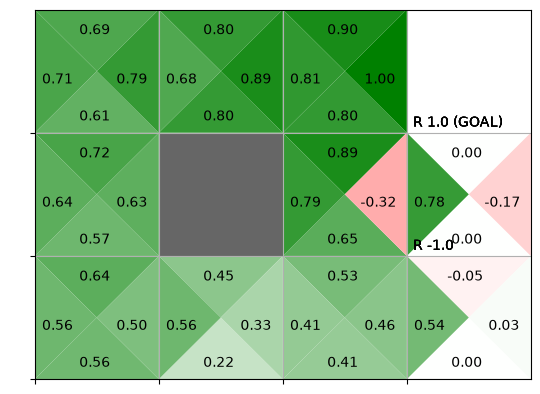

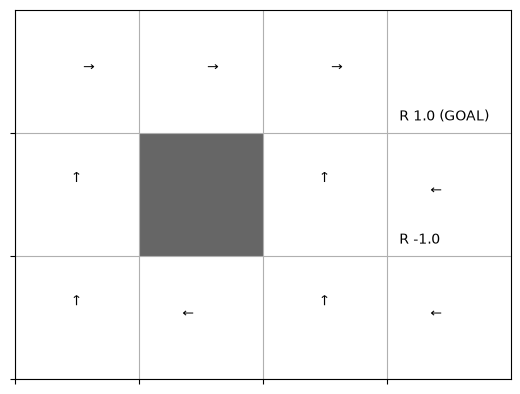

In [7]:

env = GridWorld()
agent = McAgent()

episodes = 10000
for episode in range(episodes):
    state = env.reset()
    agent.reset()

    while True:
        action = agent.get_action(state)
        next_state, reward, done = env.step(action)

        agent.add(state, action, reward)
        if done:
            agent.update()
            break

        state = next_state

# [그림 5-17] 및 [그림 5-18]
env.render_q(agent.Q)


# 중요도 샘플링

In [8]:
import numpy as np

x = np.array([1, 2, 3])         # 확률 변수
pi = np.array([0.1, 0.1, 0.8])  # 확률 분포

# =========== 기댓값의 참값 계산 ==================
e = np.sum(x * pi)
print('참값(E_pi[x]):', e)

# =========== 몬테카를로법으로 계산 ==================
n = 100  # 샘플 개수
samples = []
for _ in range(n):
    s = np.random.choice(x, p=pi)  # pi를 이용한 샘플링
    samples.append(s)

mean = np.mean(samples)  # 샘플들의 평균
var = np.var(samples)    # 샘플들의 분산
print('몬테카를로법: {:.2f} (분산: {:.2f})'.format(np.mean(samples), np.var(samples)))


참값(E_pi[x]): 2.7
몬테카를로법: 2.80 (분산: 0.28)


In [15]:
# =========== 중요도 샘플링으로 계산 ===========
x = np.array([1, 2, 3])         # 확률 변수
pi = np.array([0.1, 0.1, 0.8])  # 확률 분포

b = np.array([1/3, 1/3, 1/3])
n = 100
samples = []
for _ in range(n):
    idx = np.arange(len(b))         # b의 인덱스([0, 1, 2])
    i = np.random.choice(idx, p=b)  # b를 사용하여 샘플링
    s = x[i]
    rho = pi[i] / b[i]              # 가중치
    samples.append(rho * s)         # 샘플 데이터에 가중치를 곱해 저장
    
mean = np.mean(samples)
var = np.var(samples)
print('중요도 샘플링: {:.2f} (분산: {:.2f})'.format(np.mean(samples), np.var(samples)))


중요도 샘플링: 2.84 (분산: 10.24)


In [18]:
# =========== 중요도 샘플링으로 계산 ===========
x = np.array([1, 2, 3])         # 확률 변수
pi = np.array([0.1, 0.1, 0.8])  # 확률 분포

b = np.array([0.2, 0.2, 0.6]) # 확률 분포 변경
samples = []
for _ in range(n):
    idx = np.arange(len(b))         # b의 인덱스([0, 1, 2])
    i = np.random.choice(idx, p=b)  # b를 사용하여 샘플링
    s = x[i]
    rho = pi[i] / b[i]              # 가중치
    samples.append(rho * s)         # 샘플 데이터에 가중치를 곱해 저장
    
mean = np.mean(samples)
var = np.var(samples)
print('중요도 샘플링: {:.2f} (분산: {:.2f})'.format(np.mean(samples), np.var(samples)))


중요도 샘플링: 2.52 (분산: 2.58)
